# 04 - Hyperparameter tuning (LightGBM)

**Goal:** check whether a light tuning of LightGBM improves on its first-pass settings, without using the validation year (2016) to make the choice.

**Method**
- Time-aware cross-validation inside the training period: train on 2003-2012 and score 2013, train on 2003-2013 and score 2014, train on 2003-2014 and score 2015. The score of a configuration is the average PR-AUC over the three folds.
- Random search: the default settings plus 12 random combinations from a small grid.
- **Adoption rule (fixed in advance):** use the best random combination only if its CV PR-AUC beats the default by at least 0.005; otherwise keep the default. The validation year is only an independent check.
- Only LightGBM is tuned (the model chosen by the selection rule); random forest and XGBoost keep their first-pass settings.

In [1]:
import sys
sys.path.append("..")

import json
import pandas as pd
from sklearn.metrics import average_precision_score
from sklearn.model_selection import ParameterSampler

from src.data.split import load_data, time_split, FEATURES, LABEL
from src.evaluation.metrics import evaluate, recall_at_effort
from src.models.builders import make_lightgbm

df = load_data()
train, validation, test, late = time_split(df)

## 1. Search space and cross-validation folds

**Goal:** define the three time-ordered folds and the configurations to try. `NaN` in the table below means the default value of that setting is used.

In [2]:
folds = [(2012, 2013), (2013, 2014), (2014, 2015)]

space = {
    "num_leaves": [15, 31, 63],
    "learning_rate": [0.03, 0.05, 0.1],
    "n_estimators": [200, 300, 500],
    "min_child_samples": [20, 50, 100],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_lambda": [0, 1, 5],
}
configs = [{}] + list(ParameterSampler(space, n_iter=12, random_state=42))

## 2. Run the search

**Goal:** score every configuration with the three time-ordered folds (39 model fits, a few minutes). The chart shows how much the configurations differ; its axis is zoomed to the range of the scores, so differences look larger than they are.

In [3]:
def cv_score(params):
    scores = []
    for last_train_year, valid_year in folds:
        fold_train = train[train["year"] <= last_train_year]
        fold_valid = train[train["year"] == valid_year]
        model = make_lightgbm(**params).fit(fold_train[FEATURES], fold_train[LABEL])
        p = model.predict_proba(fold_valid[FEATURES])[:, 1]
        scores.append(average_precision_score(fold_valid[LABEL], p))
    return sum(scores) / len(scores)

search = pd.DataFrame(configs)
search.insert(0, "config", ["default"] + [f"random {i}" for i in range(1, len(configs))])
search["cv PR-AUC"] = [cv_score(c) for c in configs]
search = search.sort_values("cv PR-AUC", ascending=False).reset_index(drop=True)
search.round(4)

,config,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,learning_rate,colsample_bytree,cv PR-AUC
0,random 10,0.7,5.0,63.0,200.0,20.0,0.03,1.0,0.6511
1,random 12,0.8,1.0,63.0,300.0,50.0,0.03,0.6,0.6507
2,default,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.6496
3,random 5,0.7,0.0,63.0,200.0,100.0,0.03,1.0,0.6491
4,random 4,0.7,5.0,31.0,300.0,50.0,0.05,0.8,0.6490
5,random 1,1.0,1.0,63.0,300.0,50.0,0.03,0.8,0.6486
6,random 7,0.8,5.0,15.0,500.0,100.0,0.05,0.6,0.6479
7,random 9,0.7,5.0,15.0,200.0,50.0,0.05,0.6,0.6449
8,random 11,1.0,0.0,15.0,300.0,100.0,0.10,1.0,0.6436
9,random 8,1.0,1.0,63.0,200.0,20.0,0.10,0.8,0.6406


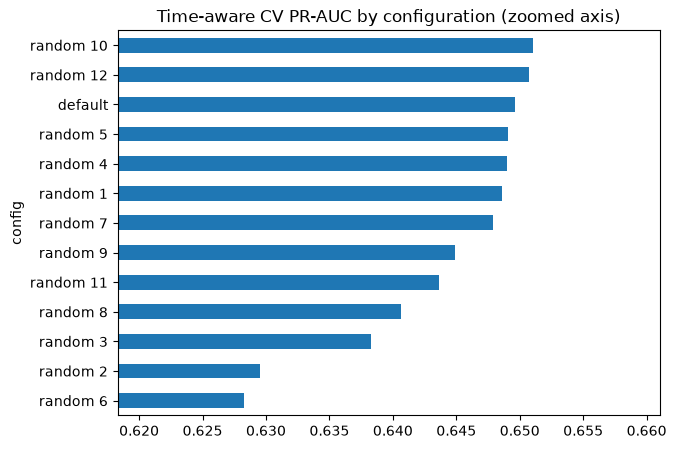

In [4]:
ax = search.set_index("config")["cv PR-AUC"].sort_values().plot(
    kind="barh", figsize=(7, 5), title="Time-aware CV PR-AUC by configuration (zoomed axis)")
ax.set_xlim(search["cv PR-AUC"].min() - 0.01, search["cv PR-AUC"].max() + 0.01)
ax.figure.savefig("../reports/figures/04_tuning_cv.png", dpi=150, bbox_inches="tight")

## 3. Apply the adoption rule and check on validation

**Goal:** compute the CV gain of the best configuration over the default and decide by the rule fixed above. Then compare the default and the best configuration on the validation year as an independent check; this check does not influence the decision.

In [5]:
default_cv = search.loc[search["config"] == "default", "cv PR-AUC"].iloc[0]
best = search.iloc[0]
gain = best["cv PR-AUC"] - default_cv
best_params = {} if best["config"] == "default" else configs[int(best["config"].split()[-1])]

print("best:", best["config"], "| gain over default:", round(gain, 4))
print("adopt tuned settings:", gain >= 0.005)

best: random 10 | gain over default: 0.0014
adopt tuned settings: False


In [6]:
effort = (validation["la"] + validation["ld"]).to_numpy()

rows = {}
for label, params in [("default", {}), ("best by CV", best_params)]:
    model = make_lightgbm(**params).fit(train[FEATURES], train[LABEL])
    p = model.predict_proba(validation[FEATURES])[:, 1]
    row = evaluate(validation[LABEL], p)
    row["Recall@20%Effort (per line)"] = recall_at_effort(validation[LABEL], p / (effort + 1), effort, 0.2)
    rows[label] = row

compare = pd.DataFrame(rows)

chosen = best_params if gain >= 0.005 else {}
with open("../results/04_lightgbm_params.json", "w") as f:
    json.dump(chosen, f, indent=2)

compare.round(3)

,default,best by CV
ROC-AUC,0.804,0.807
PR-AUC,0.630,0.633
precision,0.493,0.494
recall,0.793,0.798
F1,0.608,0.610
MCC,0.417,0.421
bug share,0.291,0.291
Recall@20%Effort (per line),0.620,0.620


**Observation**
- The configurations differ little near the top: the best one (`random 10`, CV PR-AUC 0.6511) is only 0.0014 above the default (0.6496), and the second best (0.6507) is also within 0.002. This is below the 0.005 adoption margin, so the difference is treated as noise.
- Settings that learn fast are at the bottom: all four configurations with `learning_rate=0.1` are among the worst five (0.6283 to 0.6436), possibly because of overfitting. The default (0.05) and the slower configurations (0.03) are at the top. This pattern comes from only 13 configurations.
- Independent check on the validation year: the default and the best-by-CV settings differ by at most 0.004 on every metric (ROC-AUC 0.804 vs 0.807, PR-AUC 0.630 vs 0.633, MCC 0.417 vs 0.421, Recall@20%Effort (per line) 0.620 vs 0.620), which is also within noise.

**Decision:** by the rule fixed in advance, the default settings are kept (`results/04_lightgbm_params.json` contains `{}`). Applying the model selection rule again: random forest, XGBoost and LightGBM are within 0.01 on PR-AUC and on Recall@20%Effort (per line), so LightGBM, the fastest, is the chosen model.

## Summary and decisions

- Light tuning (13 configurations, 3 time-ordered CV folds inside 2003-2015) did not beat the default LightGBM settings by the required margin (+0.0014 vs 0.005), so the defaults are kept.
- Chosen model: LightGBM with default settings (tied with random forest and XGBoost within 0.01, and the fastest). Only LightGBM was tuned.
- Next: refit logistic regression (baseline) and LightGBM on 2003-2016 and evaluate the test year once, with fixed thresholds.